# Restricciones: qué layouts son válidos

Este notebook es aparte de `TT.ipynb`; la primera celda copia de ahí el recinto, las salidas y los módulos.

Son **seis restricciones duras**, agrupadas por su origen:

| Origen | Restricción |
|---|---|
| Geométrico | **G1** dentro del recinto · **G2** sin encimarse · **G3** sin pisar muros |
| Legal (NOM-002-STPS-2010, 7.15 b y 7.16 f) | **G4** salidas despejadas · el ancho libre de circulación, que se usa en G5 y G6 |
| Criterio de diseño | **G5** no inutilizar más del 3 % del área útil · **G6** cada módulo debe ser alcanzable |

**Duras, pero medidas en grado.** Cada una no dice solo "cumple / no cumple", sino **cuánto** se viola: metros fuera, m² encimados, etc. Así el optimizador puede comparar dos layouts inválidos y moverse hacia el que viola menos (sección final).

In [1]:
# ---------- lo mismo que en TT.ipynb: recinto, salidas, módulos y campo() ----------
import numpy as np
import matplotlib.pyplot as plt
import skfmm
from enum import Enum
from dataclasses import dataclass

def pintar(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = True

def abrir(mascara, x, y, ancho, fondo):
    mascara[y:y + fondo, x:x + ancho] = False

W, H = 200, 120
muros = np.zeros((H, W), dtype=bool)
pintar(muros, 0, 12, W, 1)
for x in (20, 60, 120, 170):
    abrir(muros, x, 12, 8, 1)
pintar(muros, 80, 4, 30, 2)
pintar(muros, 110, 13, 1, H - 13)
abrir(muros, 110, 40, 1, 6)
abrir(muros, 110, 85, 1, 6)
for x in range(12, 110, 12):
    for y in range(25, H, 12):
        pintar(muros, x, y, 1, 1)
pintar(muros, 0, 95, 25, 1)
pintar(muros, 25, 95, 1, H - 95)
abrir(muros, 10, 95, 2, 1)
pintar(muros, 130, 105, 50, 15)
pintar(muros, 194, 40, 6, 20)

SALIDAS = [(30, 0, 10, 1), (140, 0, 10, 1), (0, 50, 1, 6),       # (x, y, ancho, fondo)
           (60, H - 1, 6, 1), (W - 1, 70, 1, 6), (185, H - 1, 6, 1)]
salidas = np.zeros((H, W), dtype=bool)
for s in SALIDAS:
    pintar(salidas, *s)

class Tipo(Enum):
    #                     nombre              ancho fondo  color     unidades  puerta
    SANITARIO         = ("Sanitarios",          8,   3,  "#4C9BE8",  8,      (0, 8))
    COMIDA            = ("Comida",              5,   5,  "#E8A33D",  4,      (1, 4))
    BEBIDAS           = ("Bebidas",             8,   3,  "#7BC96F",  6,      (0, 8))
    PRIMEROS_AUXILIOS = ("Primeros auxilios",   5,   5,  "#A96BE0",  2,      (2, 3))

    def __init__(self, nombre, ancho, fondo, color, unidades, puerta):
        self.nombre = nombre
        self.ancho = ancho
        self.fondo = fondo
        self.color = color
        self.unidades = unidades
        self.puerta = puerta

@dataclass
class Modulo:
    tipo: Tipo
    x: int
    y: int
    rot: int = 0

    @property
    def ancho(self):
        return self.tipo.ancho if self.rot in (0, 180) else self.tipo.fondo

    @property
    def fondo(self):
        return self.tipo.fondo if self.rot in (0, 180) else self.tipo.ancho

    def celdas_puerta(self):
        a, b = self.tipo.puerta
        x, y, w, f = self.x, self.y, self.ancho, self.fondo
        if self.rot == 0:
            return [(x + u, y - 1) for u in range(a, b)]
        if self.rot == 90:
            return [(x + w, y + u) for u in range(a, b)]
        if self.rot == 180:
            return [(x + w - 1 - u, y + f) for u in range(a, b)]
        if self.rot == 270:
            return [(x - 1, y + f - 1 - u) for u in range(a, b)]

layout = [
    Modulo(Tipo.SANITARIO, 14, 28, 0),
    Modulo(Tipo.SANITARIO, 62, 28, 180),
    Modulo(Tipo.SANITARIO, 150, 30, 0),
    Modulo(Tipo.COMIDA, 38, 64, 90),
    Modulo(Tipo.COMIDA, 86, 64, 270),
    Modulo(Tipo.COMIDA, 140, 70, 0),
    Modulo(Tipo.BEBIDAS, 50, 100, 0),
    Modulo(Tipo.BEBIDAS, 160, 95, 180),
    Modulo(Tipo.PRIMEROS_AUXILIOS, 74, 40, 90),
]

def campo(destino, bloqueado, v=None):
    if v is None:
        v = np.ones((H, W))
    phi = np.ones((H, W))
    phi[destino] = -1
    phi = np.ma.MaskedArray(phi, mask=bloqueado)
    v = np.ma.MaskedArray(np.maximum(v, 1e-3), mask=bloqueado)
    return np.ma.filled(skfmm.travel_time(phi, v, dx=1), np.inf)

def bloqueo(layout):
    """Muros + lo que ocupan los módulos."""
    b = muros.copy()
    for m in layout:
        pintar(b, m.x, m.y, m.ancho, m.fondo)
    return b

ocupado = bloqueo(layout)

In [2]:
from scipy import ndimage

def rect(m):
    return m.x, m.y, m.ancho, m.fondo

def mascara(m):
    """Las celdas que pisa el módulo (recortado al recinto)."""
    M = np.zeros((H, W), dtype=bool)
    x, y, w, f = rect(m)
    M[max(y, 0):max(y + f, 0), max(x, 0):max(x + w, 0)] = True
    return M

def interseccion(a, b):
    """Área (m²) que comparten dos rectángulos (x, y, ancho, fondo)."""
    ax, ay, aw, af = a
    bx, by, bw, bf = b
    return max(0, min(ax + aw, bx + bw) - max(ax, bx)) * max(0, min(ay + af, by + bf) - max(ay, by))

from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle

def capa(ax, M, color, alfa=1.0):
    ax.imshow(np.where(M, 1.0, np.nan), origin="lower", extent=(0, W, 0, H), cmap=ListedColormap([color]),
              alpha=alfa, vmin=0, vmax=1)

def dibujar(ax, lay, titulo, culpables=(), rojo=None, verde=None, zoom=None):
    """El recinto con sus módulos. Los culpables, con borde rojo; 'rojo' y 'verde': zonas a resaltar."""
    capa(ax, muros, "#8a8a8a")
    if verde is not None:
        capa(ax, verde, "#b7e4a8", 0.8)
    if rojo is not None:
        capa(ax, rojo, "red", 0.55)
    capa(ax, salidas, "lime")
    for i, m in enumerate(lay):
        malo = i in culpables
        ax.add_patch(Rectangle((m.x, m.y), m.ancho, m.fondo, facecolor=m.tipo.color,
                               edgecolor="red" if malo else "black", lw=2.5 if malo else 0.6, alpha=0.9))
    x0, x1, y0, y1 = zoom or (0, W, 0, H)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1); ax.set_aspect("equal")
    ax.set_title(titulo)

def cambia(lay, i, nuevo):
    """Copia del layout con el módulo i cambiado."""
    l = list(lay)
    l[i] = nuevo
    return l

## G1, G2, G3: geométricas

- **G1:** cuántos metros se sale cada módulo del recinto.
- **G2:** cuántos m² se enciman los módulos entre sí.
- **G3:** cuántos m² de módulo quedan encima de un muro.

Son las más baratas: solo rectángulos.

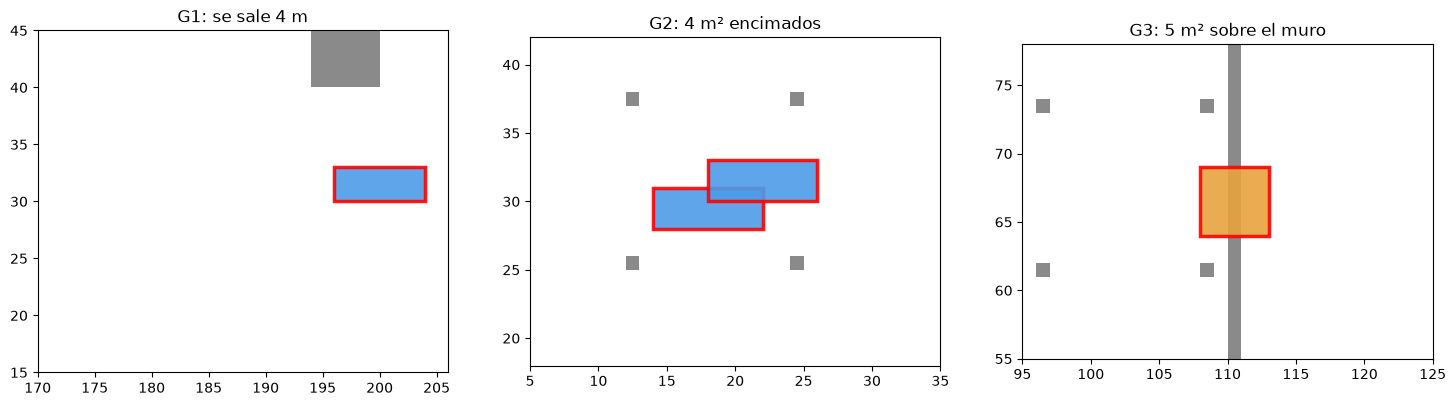

In [3]:
def g1_dentro(lay):
    v = 0.0
    for m in lay:
        x, y, w, f = rect(m)
        v += max(0, -x) + max(0, x + w - W) + max(0, -y) + max(0, y + f - H)
    return v

def g2_traslape(lay):
    return sum(interseccion(rect(a), rect(b)) for i, a in enumerate(lay) for b in lay[i + 1:])

def g3_muros(lay):
    return float(sum((mascara(m) & muros).sum() for m in lay))

fuera = cambia(layout, 2, Modulo(Tipo.SANITARIO, 196, 30, 0))     # el sanitario de la sala B, contra la pared este
encima = cambia(layout, 1, Modulo(Tipo.SANITARIO, 18, 30, 0))     # un sanitario sobre otro
en_muro = cambia(layout, 4, Modulo(Tipo.COMIDA, 108, 64, 270))    # una comida atravesando el muro divisorio

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
dibujar(ax[0], fuera, "G1: se sale %.0f m" % g1_dentro(fuera), culpables=[2], zoom=(170, 206, 15, 45))
dibujar(ax[1], encima, "G2: %.0f m² encimados" % g2_traslape(encima), culpables=[0, 1], zoom=(5, 35, 18, 42))
dibujar(ax[2], en_muro, "G3: %.0f m² sobre el muro" % g3_muros(en_muro), culpables=[4], zoom=(95, 125, 55, 78))
plt.show()

## G4: salidas despejadas

Frente a cada salida debe quedar libre un rectángulo de **1.5 × su ancho** de profundidad (valor provisional: la NOM-002 obliga a tener salidas libres, pero no fija la medida). La violación son los m² de módulo dentro de esas zonas.

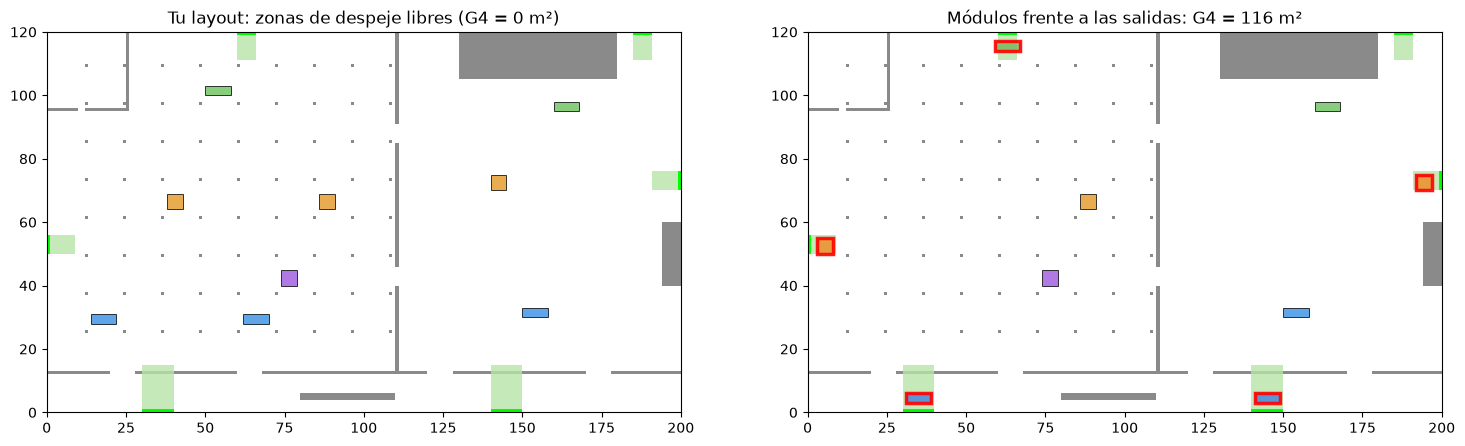

In [4]:
PROF_DESPEJE = 1.5            # × ancho de la salida. PROVISIONAL

def conos():
    """El rectángulo frente a cada salida que debe quedar libre: (x, y, ancho, fondo)."""
    c = []
    for x, y, w, f in SALIDAS:
        d = PROF_DESPEJE * max(w, f)
        if y == 0:          c.append((x, 0, w, d))           # salida en el muro sur
        elif y == H - 1:    c.append((x, H - d, w, d))       # norte
        elif x == 0:        c.append((0, y, d, f))           # oeste
        else:               c.append((W - d, y, d, f))       # este
    return c

def g4_salidas(lay):
    return sum(interseccion(rect(m), c) for m in lay for c in conos())

def mascara_rect(r):
    x, y, w, f = r
    M = np.zeros((H, W), dtype=bool)
    M[int(y):int(np.ceil(y + f)), int(x):int(np.ceil(x + w))] = True
    return M

zona_conos = np.any([mascara_rect(c) for c in conos()], axis=0)

estorbo = [
    Modulo(Tipo.SANITARIO, 31, 3, 180),          # a 2 m de la salida sur principal
    Modulo(Tipo.SANITARIO, 141, 3, 180),         # a 2 m de la segunda salida sur
    Modulo(Tipo.SANITARIO, 150, 30, 0),
    Modulo(Tipo.COMIDA, 3, 50, 90),              # a 2 m de la salida oeste
    Modulo(Tipo.COMIDA, 86, 64, 270),
    Modulo(Tipo.COMIDA, 192, 70, 270),           # a 2 m de la salida este
    Modulo(Tipo.BEBIDAS, 59, 114, 0),            # a 2 m de la salida norte de la sala A
    Modulo(Tipo.BEBIDAS, 160, 95, 180),
    Modulo(Tipo.PRIMEROS_AUXILIOS, 74, 40, 90),
]
invadido = zona_conos & np.any([mascara(m) for m in estorbo], axis=0)
culpables = [i for i, m in enumerate(estorbo) if any(interseccion(rect(m), c) > 0 for c in conos())]

fig, ax = plt.subplots(1, 2, figsize=(18, 5))
dibujar(ax[0], layout, "Tu layout: zonas de despeje libres (G4 = %.0f m²)" % g4_salidas(layout), verde=zona_conos)
dibujar(ax[1], estorbo, "Módulos frente a las salidas: G4 = %.0f m²" % g4_salidas(estorbo),
        culpables=culpables, rojo=invadido, verde=zona_conos)
plt.show()

Este es el mismo layout que en `evacuacion.ipynb` tardaba **32 % más** en evacuar: G4 existe para que eso no pueda pasar.

## G5: área útil

**La zona ocupable** es el piso al que se puede llegar desde una salida **sin pasar por un hueco de menos de 3 m** (el ancho libre de circulación, también provisional). Se calcula con morfología:

1. **Erosión:** se quita todo lo que está pegado a un estorbo. Un pasillo de $2r+1$ celdas deja una línea viva; uno más angosto desaparece.
2. **Pedazos conectados** (`ndimage.label`).
3. Se quedan solo los pedazos que **tocan una salida**.
4. **Dilatación:** se les regresa la orilla que quitó la erosión.

Un rincón detrás de un módulo al que no se entra con 3 m **no es una infracción**, es superficie que ya no se puede usar. Por eso G5 no prohíbe rincones: pide que el layout no inutilice más del **3 %** del área útil, además de lo que pisan los propios módulos.

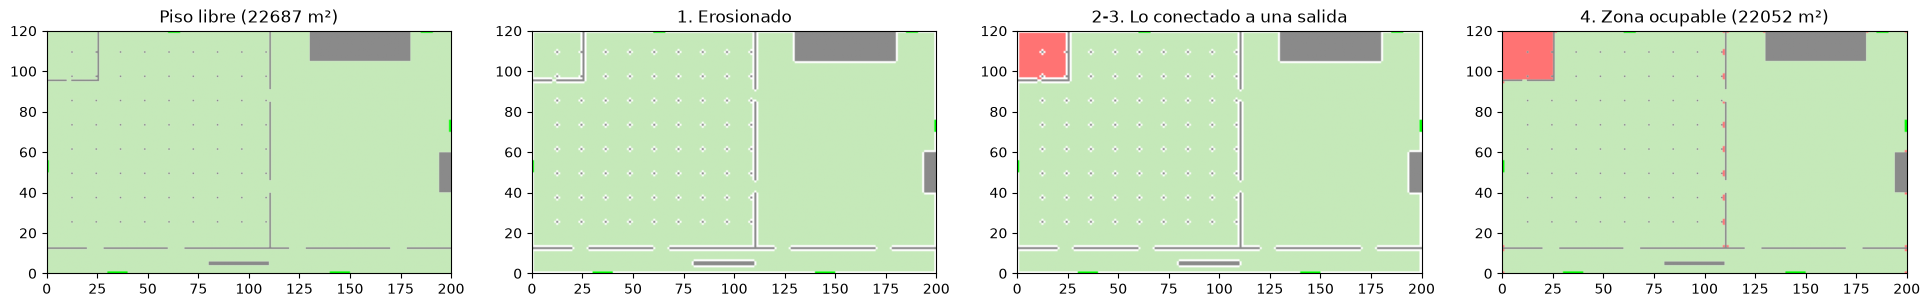

In [5]:
W_MIN = 3                     # m de ancho libre de circulación. PROVISIONAL
r = (W_MIN - 1) // 2          # con celdas de 1 m, r = 1: un pasillo de 3 celdas deja viva la de en medio
y_, x_ = np.ogrid[-r:r + 1, -r:r + 1]
disco = x_ ** 2 + y_ ** 2 <= r * r + 0.5

def zona_ocupable(lay):
    libre = ~bloqueo(lay)
    erod = ndimage.binary_erosion(libre, structure=disco)                    # 1
    lab, _ = ndimage.label(erod)                                             # 2
    cerca = ndimage.binary_dilation(salidas, structure=disco) & erod
    red = np.isin(lab, [k for k in np.unique(lab[cerca]) if k > 0])          # 3
    ocupable = ndimage.binary_dilation(red, structure=disco) & libre         # 4
    return ocupable, erod, red

oc, erod, red = zona_ocupable([])
libre = ~muros
fig, ax = plt.subplots(1, 4, figsize=(24, 3.9))
dibujar(ax[0], [], "Piso libre (%d m²)" % libre.sum(), verde=libre)
dibujar(ax[1], [], "1. Erosionado", verde=erod)
dibujar(ax[2], [], "2-3. Lo conectado a una salida", verde=red, rojo=erod & ~red)
dibujar(ax[3], [], "4. Zona ocupable (%d m²)" % oc.sum(), verde=oc, rojo=libre & ~oc)
plt.show()

**Qué ver:** la bodega de arriba a la izquierda (en rojo) no es ocupable aunque esté vacía: su puerta mide 2 m. Esa área ya estaba perdida antes de poner módulos, así que no cuenta contra ningún layout.

**El radio de la erosión, con cuidado.** Con celdas de 1 m, un pasillo de $w$ celdas sobrevive a la erosión de radio $r$ solo si $w \ge 2r + 1$. Para exigir 3 m, $r = 1$:

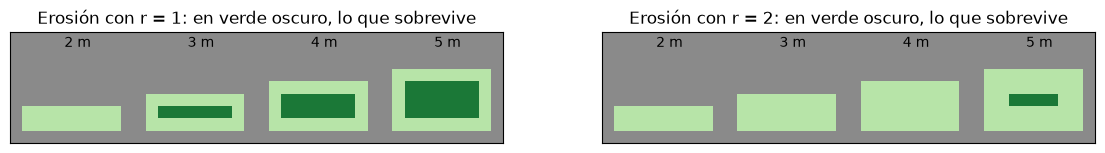

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.2))
for a, rr in zip(ax, (1, 2)):
    yy, xx = np.ogrid[-rr:rr + 1, -rr:rr + 1]
    d = xx ** 2 + yy ** 2 <= rr * rr + 0.5
    piso = np.zeros((9, 40), dtype=bool)
    vivos = []
    for k, ancho in enumerate((2, 3, 4, 5)):
        p = np.zeros((9, 40), dtype=bool)
        p[1:1 + ancho, 10 * k + 1:10 * k + 9] = True
        piso |= p
        vivos.append(ndimage.binary_erosion(p, structure=d))
    a.imshow(piso, origin="lower", cmap=ListedColormap(["#8a8a8a", "#b7e4a8"]))
    a.imshow(np.where(np.any(vivos, axis=0), 1.0, np.nan), origin="lower", cmap=ListedColormap(["#1b7837"]))
    for k, ancho in enumerate((2, 3, 4, 5)):
        a.text(10 * k + 5, 7.3, "%d m" % ancho, ha="center")
    a.set_title("Erosión con r = %d: en verde oscuro, lo que sobrevive" % rr)
    a.set_xticks([]); a.set_yticks([])
plt.show()

Con $r = 2$ un pasillo de 3 o 4 m ya no pasa: en la práctica se estaría exigiendo **5 m**. Así lo calculaba `nucleo/geometria.py` del proyecto hasta el 13 de octubre de 2026: `round(1.5 / h)` = 2, que exigía 5 m. Ya está corregido: con el radio nuevo, de los 1,776 layouts del experimento de correlación pasan a ser válidos 21 más (de 67.9 % a 69.1 %) y ninguno deja de serlo.

Ahora un layout que sí viola G5: dos sanitarios parten el vestíbulo (dejan 2 m arriba y 2 m abajo) y las bebidas tapan dos puertas interiores (dejan 1 m). El pedazo de en medio queda sin salida legal.

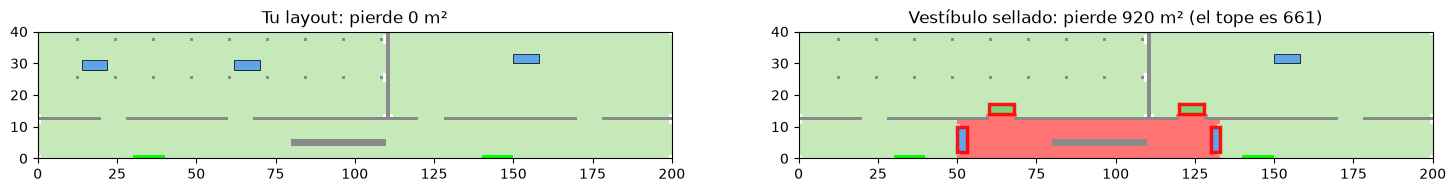

G5 = 258 m² por encima del tope


In [7]:
PERDIDA_MAX = 0.03            # criterio de diseño del proyecto

def g5_area(lay):
    base = zona_ocupable([])[0].sum()
    con = zona_ocupable(lay)[0].sum()
    servicios = sum(m.ancho * m.fondo for m in lay)
    perdida = max(0, base - con - servicios)
    return max(0, perdida - PERDIDA_MAX * base), perdida, base

sellado = [
    Modulo(Tipo.SANITARIO, 50, 2, 90),           # parte el vestíbulo: deja 2 m arriba y 2 m abajo
    Modulo(Tipo.SANITARIO, 130, 2, 90),
    Modulo(Tipo.SANITARIO, 150, 30, 0),
    Modulo(Tipo.COMIDA, 38, 64, 90),
    Modulo(Tipo.COMIDA, 86, 64, 270),
    Modulo(Tipo.COMIDA, 140, 70, 0),
    Modulo(Tipo.BEBIDAS, 60, 14, 180),           # tapa la puerta interior de x = 60: deja 1 m
    Modulo(Tipo.BEBIDAS, 120, 14, 180),          # tapa la puerta interior de x = 120
    Modulo(Tipo.PRIMEROS_AUXILIOS, 74, 40, 90),
]
oc_base = zona_ocupable([])[0]
oc_sell = zona_ocupable(sellado)[0]
perdido = oc_base & ~oc_sell & ~np.any([mascara(m) for m in sellado], axis=0)
v, perdida, base = g5_area(sellado)

fig, ax = plt.subplots(1, 2, figsize=(18, 4))
dibujar(ax[0], layout, "Tu layout: pierde %d m²" % g5_area(layout)[1], verde=zona_ocupable(layout)[0], zoom=(0, W, 0, 40))
dibujar(ax[1], sellado, "Vestíbulo sellado: pierde %d m² (el tope es %d)" % (perdida, PERDIDA_MAX * base),
        culpables=[0, 1, 6, 7], verde=oc_sell, rojo=perdido, zoom=(0, W, 0, 40))
plt.show()
print("G5 = %.0f m² por encima del tope" % v)

## G6: cada módulo debe ser alcanzable

Cada módulo necesita al menos **3 m de orilla** que den a la zona ocupable; si no, nadie puede llegar a usarlo.

¿Por qué no basta con G5? Un sanitario dentro de la bodega no pisa nada, no estorba salidas, y como la bodega **ya estaba perdida**, tampoco le quita área útil a nadie. Pasa G1 a G5 siendo un módulo al que nadie llega.

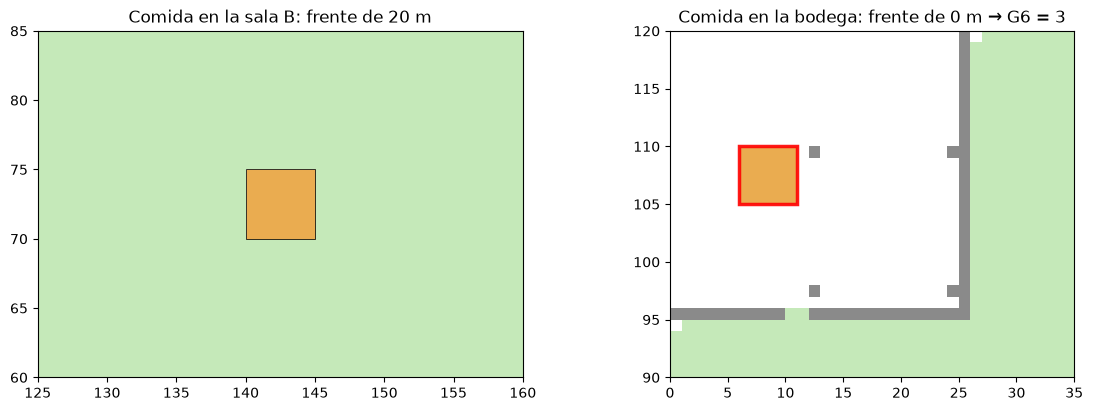

In [8]:
FRENTE_MIN = 3
cruz = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool)

def frente(m, ocupable):
    """Metros de orilla del módulo que dan a piso ocupable."""
    M = mascara(m)
    anillo = ndimage.binary_dilation(M, structure=cruz) & ~M
    return float((anillo & ocupable).sum())

def g6_alcanzable(lay):
    oc = zona_ocupable(lay)[0]
    return sum(max(0, FRENTE_MIN - frente(m, oc)) for m in lay)

en_bodega = cambia(layout, 5, Modulo(Tipo.COMIDA, 6, 105, 0))
oc = zona_ocupable(en_bodega)[0]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
dibujar(ax[0], layout, "Comida en la sala B: frente de %.0f m" % frente(layout[5], zona_ocupable(layout)[0]),
        verde=zona_ocupable(layout)[0], zoom=(125, 160, 60, 85))
dibujar(ax[1], en_bodega, "Comida en la bodega: frente de %.0f m → G6 = %.0f" % (frente(en_bodega[5], oc), g6_alcanzable(en_bodega)),
        culpables=[5], verde=oc, zoom=(0, 35, 90, 120))
plt.show()

## Todas juntas

Se evalúan de la más barata a la más cara: primero rectángulos (G1–G4), luego morfología (G5, G6). Dentro del optimizador basta con encontrar la primera que falla.

In [9]:
def evaluar(lay):
    v = {"G1": g1_dentro(lay), "G2": g2_traslape(lay), "G3": g3_muros(lay),
         "G4": g4_salidas(lay), "G5": g5_area(lay)[0], "G6": g6_alcanzable(lay)}
    return v, sum(v.values())

ejemplos = {"tu layout": layout, "fuera": fuera, "encima": encima, "en el muro": en_muro,
            "frente a salidas": estorbo, "vestíbulo sellado": sellado, "en la bodega": en_bodega}
print("%-18s" % "" + "".join("%8s" % k for k in ("G1", "G2", "G3", "G4", "G5", "G6")) + "   violación total")
for nombre, lay in ejemplos.items():
    v, total = evaluar(lay)
    print("%-18s" % nombre + "".join("%8.1f" % x for x in v.values()) + "   %8.1f %s" % (total, "válido" if total == 0 else ""))

                        G1      G2      G3      G4      G5      G6   violación total
tu layout              0.0     0.0     0.0     0.0     0.0     0.0        0.0 válido
fuera                  4.0     0.0     0.0     0.0     0.0     0.0        4.0 
encima                 0.0     4.0     0.0     0.0     0.0     0.0        4.0 
en el muro             0.0     0.0     5.0     0.0     0.0     0.0        5.0 
frente a salidas       0.0     0.0     0.0   116.0     0.0     0.0      116.0 
vestíbulo sellado      0.0     0.0     0.0     0.0   258.4     0.0      258.4 
en la bodega           0.0     0.0     0.0     0.0     0.0     3.0        3.0 


**¿Para qué sirve medir en grado?** En NSGA-II los layouts inválidos no se tiran: compiten con la **dominancia restringida** de Deb (2000).
1. Un válido le gana a cualquier inválido.
2. Entre dos inválidos, gana el que viola menos (la violación total de arriba).
3. Entre dos válidos, se comparan los objetivos.

Así no hay que inventar un peso que mezcle metros de violación con segundos de evacuación. Solo la población inicial se arma por rechazo: se proponen layouts al azar hasta tener puros válidos. Eso se ve en `multiobjetivo.ipynb`.

**¿Y los 40 m de la NOM-002?** La norma pide que ningún punto esté a más de 40 m de una salida o, si no, que la evacuación tome máximo 3 minutos (7.15 d). En este recinto el punto más lejano ya está a 84 m **sin módulos**, así que como restricción invalidaría todos los layouts por una causa ajena a ellos. Se revisa por recinto, no por layout; la parte del tiempo la mide $f_2$.

**Valores provisionales**, mientras se confirma su fuente: el ancho libre de 3 m, el despeje de 1.5 × ancho, el 3 % de área perdida y los 3 m de frente.

## Referencias

- Secretaría del Trabajo y Previsión Social (2010). NOM-002-STPS-2010, *Condiciones de seguridad — Prevención y protección contra incendios en los centros de trabajo*. Diario Oficial de la Federación.
- Deb, K. (2000). An efficient constraint handling method for genetic algorithms. *Computer Methods in Applied Mechanics and Engineering*, 186(2–4), 311–338.